In [1]:
# importing the libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import GroupShuffleSplit
import lightkurve as lk

pd.set_option("display.max_columns", None)

c:\Users\sagal\anaconda3\envs\exoplanet\lib\site-packages\lightkurve\prf\__init__.py:7: UserWarning: Warning: the tpfmodel submodule is not available without oktopus installed, which requires a current version of autograd. See #1452 for details.
  warnings.warn(


In [2]:
#reproducibility
import random
import numpy as np

SEED = 42

random.seed(SEED)
np.random.seed(SEED)

In [3]:
#read the data using pandas

tce = pd.read_csv('../dataset/q1_q17_dr24_tce_2026.11.16_11.35.38.csv', comment = '#')

In [4]:
print(tce.shape)

(20367, 155)


In [5]:
tce.head()

,kepid,tce_plnt_num,tce_rogue_flag,tce_delivname,rowupdate,tce_datalink_dvs,tce_datalink_dvr,tce_period,tce_period_err,tce_time0bk,tce_time0bk_err,tce_time0,tce_time0_err,tce_ror,tce_ror_err,tce_dor,tce_dor_err,tce_incl,tce_incl_err,tce_impact,tce_impact_err,tce_duration,tce_duration_err,tce_ingress,tce_ingress_err,tce_depth,tce_depth_err,tce_eccen,tce_eccen_err,tce_longp,tce_longp_err,tce_limbdark_mod,tce_ldm_coeff1,tce_ldm_coeff2,tce_ldm_coeff3,tce_ldm_coeff4,tce_num_transits,tce_trans_mod,tce_full_conv,tce_model_snr,tce_model_chisq,tce_model_dof,tce_robstat,tce_dof1,tce_dof2,tce_chisq1,tce_chisq2,tce_chisqgofdof,tce_chisqgof,tce_prad,tce_prad_err,tce_sma,tce_sma_err,tce_eqt,tce_eqt_err,tce_insol,tce_insol_err,tce_nkoi,tce_ioflag,tce_quarters,tce_steff,tce_steff_err,tce_slogg,tce_slogg_err,tce_smet,tce_smet_err,tce_sradius,tce_sradius_err,tce_steff_prov,tce_slogg_prov,tce_smet_prov,tce_sradius_prov,tcet_period,tcet_period_err,tcet_time0bk,tcet_time0bk_err,tcet_time0,tcet_time0_err,tcet_duration,tcet_duration_err,tcet_ingress,tcet_ingress_err,tcet_depth,tcet_depth_err,tcet_full_conv,tcet_model_chisq,tcet_model_dof,wst_robstat,wst_depth,tce_mesmedian,tce_mesmad,tce_maxmes,tce_minmes,tce_maxmesd,tce_minmesd,tce_max_sngle_ev,tce_max_mult_ev,tce_bin_oedp_stat,tce_rmesmad,tce_rsnrmes,tce_rminmes,tce_albedo,tce_albedo_err,tce_ptemp,tce_ptemp_err,tce_albedo_stat,tce_ptemp_stat,av_vf_pc,av_vf_pc_err,av_vf_afp,av_vf_afp_err,av_vf_ntp,av_vf_ntp_err,av_pp_pc,av_pp_afp,av_pp_ntp,av_training_set,av_pred_class,boot_fap,boot_mesthresh,boot_mesmean,boot_messtd,tce_cap_stat,tce_hap_stat,tce_rb_tpdur,tce_rb_tcount0,tce_rb_tcount1,tce_rb_tcount2,tce_rb_tcount3,tce_rb_tcount4,tce_fwm_stat,tce_fwm_sra,tce_fwm_sra_err,tce_fwm_sdec,tce_fwm_sdec_err,tce_fwm_srao,tce_fwm_srao_err,tce_fwm_sdeco,tce_fwm_sdeco_err,tce_fwm_prao,tce_fwm_prao_err,tce_fwm_pdeco,tce_fwm_pdeco_err,tce_dicco_mra,tce_dicco_mra_err,tce_dicco_mdec,tce_dicco_mdec_err,tce_dicco_msky,tce_dicco_msky_err,tce_dikco_mra,tce_dikco_mra_err,tce_dikco_mdec,tce_dikco_mdec_err,tce_dikco_msky,tce_dikco_msky_err
0,1162345,2,NaN,q1_q17_dr24_tce,2015-01-15,001/001162/001162345/dv/kplr001162345-002-2014...,001/001162/001162345/dv/kplr001162345-20141002...,0.831850,0.000067,132.227,0.035197,2454970.0,0.035197,0.002704,0.004213,1.022012,0.403246,25.04,243.10,0.92600,1.471,2.392,21.0000,0.04453,0.51160,6.092,2.636,0,0,0,0,claret_nonlinear_limb_darkening_model_2011,0.281886,0.984398,-0.889167,0.297218,1609,mandel-agol_geometric_transit_model,1,2.950,22280.0,26290.0,13.410,20620.0,1585,30740.0,4783.00,NaN,NaN,0.5099,0.7944,0.01877,1.007000e-06,2760.0,637.0,NaN,NaN,0,NaN,11111111111111111,6510.0,207.0,4.07,0.26,-0.24,0.30,1.728,0.791,PHO1,KIC0,KIC0,DSEP,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,4.3090,10.90000,-6.388,0.5569,0.4381,4.959,10.410,1.097000e-03,2.416,0.2834,0.6137,NaN,NaN,NaN,NaN,NaN,NaN,0.0031,0.0027,99.4727,0.0423,0.5241,0.0423,0.0000,99.9224,0.0776,AFP,AFP,1.848600e-57,2.2715,-4.18050,0.91566,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,24.3430,19.418054,0.000055,36.855089,0.000807,2.2230,2.360,6.187,2.91,-0.000017,0.000014,-0.000039,0.000018,-0.055177,1.1300,0.504060,1.2900,0.507070,1.1200,-0.183490,1.2100,0.424890,1.3000,0.46282,1.1000
1,1292087,2,NaN,q1_q17_dr24_tce,2015-01-15,001/001292/001292087/dv/kplr001292087-002-2014...,001/001292/001292087/dv/kplr001292087-20141002...,1.095240,0.000010,132.133,0.002685,2454970.0,0.002685,0.005440,0.003881,3.834003,12.984626,86.17,212.40,0.25630,13.310,2.122,0.4755,0.01228,0.09518,34.530,4.427,0,0,0,0,claret_nonlinear_limb_darkening_model_2011,0.360591,0.737616,-0.567858,0.166028,1218,mandel-agol_geometric_transit_model,1,10.600,16100.0,18180.0,10.430,15520.0,1193,19800.0,2261.00,NaN,NaN,0.8916,0.6361,0.02187,1.344000e-07,2310.0,661.0,NaN,NaN,0,NaN,11111111111111111,6328.0,207.0,4.15,0.29,-0.08,0.30,1.502,0.852,PHO1,KIC0,KIC0,DSEP,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.4430,5.72200,-5.308,0.6473

In [6]:
#keep all the column names to the list
tce.columns.tolist()

['kepid',
 'tce_plnt_num',
 'tce_rogue_flag',
 'tce_delivname',
 'rowupdate',
 'tce_datalink_dvs',
 'tce_datalink_dvr',
 'tce_period',
 'tce_period_err',
 'tce_time0bk',
 'tce_time0bk_err',
 'tce_time0',
 'tce_time0_err',
 'tce_ror',
 'tce_ror_err',
 'tce_dor',
 'tce_dor_err',
 'tce_incl',
 'tce_incl_err',
 'tce_impact',
 'tce_impact_err',
 'tce_duration',
 'tce_duration_err',
 'tce_ingress',
 'tce_ingress_err',
 'tce_depth',
 'tce_depth_err',
 'tce_eccen',
 'tce_eccen_err',
 'tce_longp',
 'tce_longp_err',
 'tce_limbdark_mod',
 'tce_ldm_coeff1',
 'tce_ldm_coeff2',
 'tce_ldm_coeff3',
 'tce_ldm_coeff4',
 'tce_num_transits',
 'tce_trans_mod',
 'tce_full_conv',
 'tce_model_snr',
 'tce_model_chisq',
 'tce_model_dof',
 'tce_robstat',
 'tce_dof1',
 'tce_dof2',
 'tce_chisq1',
 'tce_chisq2',
 'tce_chisqgofdof',
 'tce_chisqgof',
 'tce_prad',
 'tce_prad_err',
 'tce_sma',
 'tce_sma_err',
 'tce_eqt',
 'tce_eqt_err',
 'tce_insol',
 'tce_insol_err',
 'tce_nkoi',
 'tce_ioflag',
 'tce_quarters',
 'tce_

In [7]:
tce.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20367 entries, 0 to 20366
Columns: 155 entries, kepid to tce_dikco_msky_err
dtypes: float64(132), int64(11), object(12)
memory usage: 24.1+ MB


In [8]:
#labels inspection

tce["av_training_set"].value_counts(dropna=False)

av_training_set
AFP    9596
UNK    4630
PC     3600
NTP    2541
Name: count, dtype: int64

In [9]:
#all possible labels
tce["av_training_set"].unique()

array(['AFP', 'UNK', 'PC', 'NTP'], dtype=object)

out of all the available labels we cannot use UNK labels which mean unknown the dip doesnt resemble any of the known criteria, inducing this data will cause noise and we cannot train our models on noise so we have to filter these DNK rows out.

In [10]:
tce = tce[
    tce["av_training_set"].isin(
        ["PC", "AFP", "NTP"]
    )
].copy()


In [11]:
tce.shape

(15737, 155)

Label encoding of the target variable where the PC->1, rest are 0

In [12]:
tce["planet"] = (
    tce["av_training_set"] == "PC"
).astype(int)

tce[["av_training_set", "planet"]].head(10)

,av_training_set,planet
0,AFP,0
3,AFP,0
5,PC,1
6,NTP,0
7,AFP,0
13,AFP,0
14,AFP,0
15,AFP,0
16,AFP,0
17,AFP,0


Now it is time to split the data we are going to do it starwise, because:
example
star A has 3 signals

TCE 1
TCE 2
TCE 3

If we randomly split rows:

TCE 1 -> Train
TCE 2 -> Test
TCE 3 -> Train

the model has already seen the same star in training.

That's cheating.

The test score becomes artificially high.

This is what it is going to be
Star A -> Train only

Star B -> Test only

Star C -> Train only

Star D -> Test only

In [13]:
#starbased splitting by using groupshuffleshift

gss = GroupShuffleSplit(
    n_splits=1,
    test_size=0.1,
    random_state=42
)

train_idx, test_idx = next(
    gss.split(
        tce,
        groups=tce["kepid"]
    )
)

In [14]:
#create test and train datasets:

train = tce.iloc[train_idx]
test = tce.iloc[test_idx]

#check sizes
print("Train shape:", train.shape)
print("Test shape:", test.shape)

Train shape: (14193, 156)
Test shape: (1544, 156)


In [15]:
#check data leakage after splitting

train_stars = set(train["kepid"])
test_stars = set(test["kepid"])

len(train_stars.intersection(test_stars))

0

In [16]:
#now we have to import the light curve for the stars, but we will do for one star first before we download everything
#one training example

train.iloc[0][
    ["kepid", "tce_period",
     "tce_time0bk", "tce_duration",
     "av_training_set"]
]

kepid              1162345
tce_period         0.83185
tce_time0bk        132.227
tce_duration         2.392
av_training_set        AFP
Name: 0, dtype: object

In [17]:
#extract the star ID

sample_star = train.iloc[0]["kepid"]

sample_star

np.int64(1162345)

In [18]:
#search for the available observations  data with NASA(MAST data)

search = lk.search_lightcurve(
    f"KIC {sample_star}",
    mission="Kepler",
    cadence="long"
)

search

#,mission,year,author,exptime,target_name,distance
,,,,s,,arcsec
0,Kepler Quarter 00,2009,Kepler,1800,kplr001162345,0.0
1,Kepler Quarter 01,2009,Kepler,1800,kplr001162345,0.0
2,Kepler Quarter 02,2009,Kepler,1800,kplr001162345,0.0
3,Kepler Quarter 03,2009,Kepler,1800,kplr001162345,0.0
4,Kepler Quarter 04,2010,Kepler,1800,kplr001162345,0.0
5,Kepler Quarter 05,2010,Kepler,1800,kplr001162345,0.0
6,Kepler Quarter 06,2010,Kepler,1800,kplr001162345,0.0
7,Kepler Quarter 07,2010,Kepler,1800,kplr001162345,0.0
8,Kepler Quarter 08,2011,Kepler,1800,kplr001162345,0.0


In [19]:
#confirmed that data availble now we will download the data

lc_collection = search.download_all()

In [20]:
#check the downloaded data
type(lc_collection)

lightkurve.collections.LightCurveCollection

In [21]:
len(lc_collection)

18

In [22]:
#the length is 18 which confirms that the all available data from 18 quarters is downloaded, now we will combine all of them into single light curve

lc = lc_collection.stitch()
type(lc)

lightkurve.lightcurve.KeplerLightCurve

In [23]:
lc

time,flux,flux_err,quality,timecorr,centroid_col,centroid_row,cadenceno,sap_flux,sap_flux_err,sap_bkg,sap_bkg_err,pdcsap_flux,pdcsap_flux_err,sap_quality,psf_centr1,psf_centr1_err,psf_centr2,psf_centr2_err,mom_centr1,mom_centr1_err,mom_centr2,mom_centr2_err,pos_corr1,pos_corr2
,,,,d,pix,pix,,electron / s,electron / s,electron / s,electron / s,electron / s,electron / s,,pix,pix,pix,pix,pix,pix,pix,pix,pix,pix
Time,float32,float32,int32,float32,float64,float64,int32,float32,float32,float32,float32,float32,float32,int32,float64,float32,float64,float32,float64,float32,float64,float32,float32,float32
120.53929492497264,1.0000863e+00,5.6677825e-05,0,1.142505e-03,289.21262,205.81790,568,2.6979831e+05,1.4878345e+01,2.1576792e+03,7.4867624e-01,3.0652244e+05,1.7371527e+01,0,———,———,———,———,289.21262,5.7136975e-05,205.81790,6.9561793e-05,6.8633663e-03,1.0544733e-02
120.55972957620543,1.0000625e+00,5.6624518e-05,10000000,1.143556e-03,289.21218,205.81751,569,2.6980009e+05,1.4879478e+01,2.1556318e+03,7.4673980e-01,3.0651516e+05,1.7355188e+01,10000000,———,———,———,———,289.21218,5.7129873e-05,205.81751,6.9583468e-05,6.3577997e-03,9.8227421e-03
120.58016412743746,9.9981219e-01,5.6570650e-05,0,1.144607e-03,289.21153,205.81730,570,2.6971338e+05,1.4876311e+01,2.1568813e+03,7.4556702e-01,3.0643844e+05,1.7338678e+01,0,———,———,———,———,289.21153,5.7143483e-05,205.81730,6.9575959e-05,5.6940536e-03,9.8609608e-03
120.60059887866373,1.0000011e+00,5.6671528e-05,0,1.145659e-03,289.21102,205.81743,571,2.6976697e+05,1.4877418e+01,2.1544265e+03,7.4792796e-01,3.0649631e+05,1.7369596e+01,0,———,———,———,———,289.21102,5.7135949e-05,205.81743,6.9561545e-05,5.1382119e-03,1.0033830e-02
120.6210335297801,9.9973369e-01,5.6559249e-05,0,1.146710e-03,289.21033,205.81719,572,2.6966231e+05,1.4875212e+01,2.1561992e+03,7.4605048e-01,3.0641438e+05,1.7335184e+01,0,———,———,———,———,289.21033,5.7150526e-05,205.81719,6.9585476e-05,4.1674436e-03,9.5684975e-03
120.6414680807793,9.9985123e-01,5.6669622e-05,0,1.147761e-03,289.21013,205.81808,573,2.6969941e+05,1.4878359e+01,2.1534470e+03,7.4690884e-01,3.0645041e+05,1.7369013e+01,0,———,———,———,———,289.21013,5.7144433e-05,205.81808,6.9573209e-05,3.9376542e-03,1.0163635e-02
120.66190273177199,9.9973184e-01,5.6650661e-05,10000000000000,1.148812e-03,289.20968,205.81712,574,2.6965400e+05,1.4875023e+01,2.1545752e+03,7.4664181e-01,3.0641381e+05,1.7363201e+01,10000000000000,———,———,———,———,289.20968,5.7150737e-05,205.81712,6.9584610e-05,3.5063371e-03,9.5496811e-03
120.68233748277271,9.9998349e-01,5.6687702e-05,0,1.149863e-03,289.20963,205.81726,575,2.6971094e+05,1.4878546e+01,2.1561716e+03,7.4675703e-01,3.0649094e+05,1.7374554e+01,0,———,———,———,———,289.20963,5.7140936e-05,205.81726,6.9572285e-05,3.4218598e-03,9.5770210e-03


In [24]:
#delete alll the missing values

lc_clean = lc.remove_nans()

lc_clean

time,flux,flux_err,quality,timecorr,centroid_col,centroid_row,cadenceno,sap_flux,sap_flux_err,sap_bkg,sap_bkg_err,pdcsap_flux,pdcsap_flux_err,sap_quality,psf_centr1,psf_centr1_err,psf_centr2,psf_centr2_err,mom_centr1,mom_centr1_err,mom_centr2,mom_centr2_err,pos_corr1,pos_corr2
,,,,d,pix,pix,,electron / s,electron / s,electron / s,electron / s,electron / s,electron / s,,pix,pix,pix,pix,pix,pix,pix,pix,pix,pix
Time,float32,float32,int32,float32,float64,float64,int32,float32,float32,float32,float32,float32,float32,int32,float64,float32,float64,float32,float64,float32,float64,float32,float32,float32
120.53929492497264,1.0000863e+00,5.6677825e-05,0,1.142505e-03,289.21262,205.81790,568,2.6979831e+05,1.4878345e+01,2.1576792e+03,7.4867624e-01,3.0652244e+05,1.7371527e+01,0,———,———,———,———,289.21262,5.7136975e-05,205.81790,6.9561793e-05,6.8633663e-03,1.0544733e-02
120.55972957620543,1.0000625e+00,5.6624518e-05,10000000,1.143556e-03,289.21218,205.81751,569,2.6980009e+05,1.4879478e+01,2.1556318e+03,7.4673980e-01,3.0651516e+05,1.7355188e+01,10000000,———,———,———,———,289.21218,5.7129873e-05,205.81751,6.9583468e-05,6.3577997e-03,9.8227421e-03
120.58016412743746,9.9981219e-01,5.6570650e-05,0,1.144607e-03,289.21153,205.81730,570,2.6971338e+05,1.4876311e+01,2.1568813e+03,7.4556702e-01,3.0643844e+05,1.7338678e+01,0,———,———,———,———,289.21153,5.7143483e-05,205.81730,6.9575959e-05,5.6940536e-03,9.8609608e-03
120.60059887866373,1.0000011e+00,5.6671528e-05,0,1.145659e-03,289.21102,205.81743,571,2.6976697e+05,1.4877418e+01,2.1544265e+03,7.4792796e-01,3.0649631e+05,1.7369596e+01,0,———,———,———,———,289.21102,5.7135949e-05,205.81743,6.9561545e-05,5.1382119e-03,1.0033830e-02
120.6210335297801,9.9973369e-01,5.6559249e-05,0,1.146710e-03,289.21033,205.81719,572,2.6966231e+05,1.4875212e+01,2.1561992e+03,7.4605048e-01,3.0641438e+05,1.7335184e+01,0,———,———,———,———,289.21033,5.7150526e-05,205.81719,6.9585476e-05,4.1674436e-03,9.5684975e-03
120.6414680807793,9.9985123e-01,5.6669622e-05,0,1.147761e-03,289.21013,205.81808,573,2.6969941e+05,1.4878359e+01,2.1534470e+03,7.4690884e-01,3.0645041e+05,1.7369013e+01,0,———,———,———,———,289.21013,5.7144433e-05,205.81808,6.9573209e-05,3.9376542e-03,1.0163635e-02
120.66190273177199,9.9973184e-01,5.6650661e-05,10000000000000,1.148812e-03,289.20968,205.81712,574,2.6965400e+05,1.4875023e+01,2.1545752e+03,7.4664181e-01,3.0641381e+05,1.7363201e+01,10000000000000,———,———,———,———,289.20968,5.7150737e-05,205.81712,6.9584610e-05,3.5063371e-03,9.5496811e-03
120.68233748277271,9.9998349e-01,5.6687702e-05,0,1.149863e-03,289.20963,205.81726,575,2.6971094e+05,1.4878546e+01,2.1561716e+03,7.4675703e-01,3.0649094e+05,1.7374554e+01,0,———,———,———,———,289.20963,5.7140936e-05,205.81726,6.9572285e-05,3.4218598e-03,9.5770210e-03


In [25]:
print(len(lc))
print(len(lc_clean))

65504
65264


<Axes: xlabel='Time - 2454833 [BKJD days]', ylabel='Normalized Flux'>

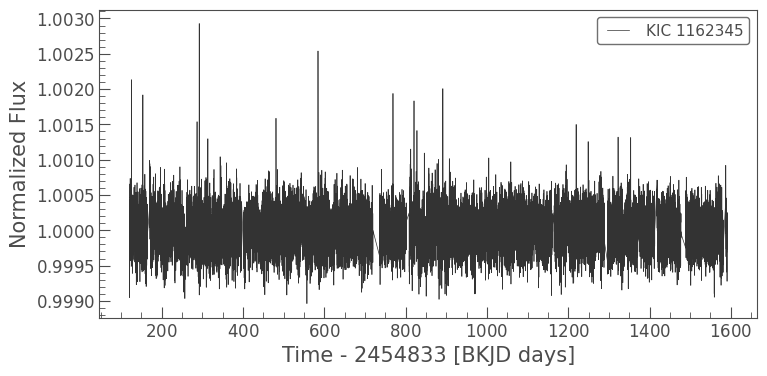

In [26]:
#visualization

lc_clean.plot()

graph:
x-axis: BKJD days => observation time
y-axis: Normalized flux => star brightness ehre 1.0000 means normal brightness

The tall upward spikes are usually instrument noises or measurement artifacts

We are going to identify the transit's period, start time, and duration from the TCE record so that we can tell the algorithm exactly where the planet-like dips occur, allowing us to mask them during flattening and preserve the transit signal instead of accidentally smoothing it away. 🚀

In [27]:
sample_row = train.iloc[0]

sample_row[
    [
        "kepid",
        "tce_period",
        "tce_time0bk",
        "tce_duration",
        "planet"
    ]
]

kepid           1162345
tce_period      0.83185
tce_time0bk     132.227
tce_duration      2.392
planet                0
Name: 0, dtype: object

We are using the period, transit time and duration from this row to tell Lightkurve exactly where the suspected transit events occur so that we can protect those dips while removing long-term stellar brightness trends.

In [29]:
period = sample_row["tce_period"]
t0 = sample_row["tce_time0bk"]
duration_hr = sample_row["tce_duration"]

duration_days = duration_hr / 24

In [30]:
print(f"Period (days): {period}")
print(f"Transit time: {t0}")
print(f"Duration (hours): {duration_hr}")
print(f"Duration (days): {duration_days}")

Period (days): 0.83185
Transit time: 132.227
Duration (hours): 2.392
Duration (days): 0.09966666666666667


We extracted the transit characteristics for this candidate signal so we can precisely identify where the expected dips occur in the star's brightness data and preserve them during preprocessing.

In [31]:
mask = lc_clean.create_transit_mask(
    period=period,
    transit_time=t0,
    duration=2 * duration_days
)

In [34]:
mask


array([ True,  True,  True, ..., False, False, False], shape=(65264,))

In [33]:
mask.sum()

np.int64(15640)

In [35]:
#flatten the light curve
flat = lc_clean.flatten(
    window_length=401,
    mask=mask
)

We are removing slow changes in the star's brightness while preserving the suspected transit events so that the transit signal becomes easier to detect and analyse.

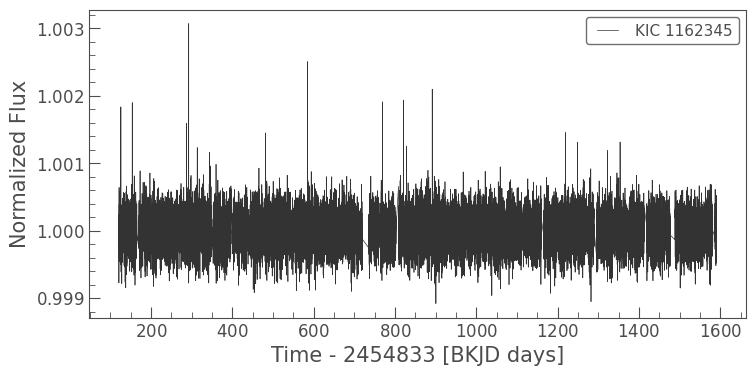

In [39]:
ax = flat.plot()
plt.show()

flattenijng completed, now folding

We are folding the light curve using the known orbital period so that all transit events line up at the same phase, making the transit signal much clearer and easier for the CNN to learn.

In [40]:
t = flat.time.value
f = flat.flux.value

phase = (
    (t - t0 + period / 2) % period
) - period / 2

In [41]:
phase[:10]

array([-0.04180508, -0.02137042, -0.00093587,  0.01949888,  0.03993353,
        0.06036808,  0.08080273,  0.10123748,  0.12167203,  0.14210668])

In [42]:
#create binning function

def binned(phase, flux, lo, hi, n):
    edges = np.linspace(lo, hi, n + 1)
    idx = np.digitize(phase, edges) - 1

    out = np.array([
        np.median(flux[idx == i])
        if (idx == i).any()
        else np.nan
        for i in range(n)
    ])

    out[np.isnan(out)] = np.nanmedian(out)

    return out

We create a binning function to compress thousands of phase-folded observations into a fixed-size representation that can be fed into the neural network.

In [43]:
#create our first global view

glob = binned(
    phase,
    f,
    -period / 2,
    period / 2,
    2001
)


In [45]:
glob[:10]

array([1.00002283, 1.00002563, 1.00005102, 1.00000989, 0.99998695,
       1.00001275, 1.00002643, 1.        , 1.00002217, 0.99997526])

In [44]:
glob.shape

(2001,)

let us create the local view noww

In [46]:
loc = binned(
    phase,
    f,
    -4 * duration_days,
    4 * duration_days,
    201
)

In [47]:
loc.shape

(201,)

Google Maps
City Level  => global view

Google Maps
Street Level => local view

the CNN will later use both these levels to predict if the dip is caused by a planet or not a planet

In [48]:
#calculate the transit depth

depth = 1 - np.median(
    f[np.abs(phase) < duration_days / 2]
)

depth

MaskedNDArray(2.249286e-05)

In [49]:
print(depth)

2.2492859982126134e-05


In [50]:
#normalization

norm = lambda v: (
    v - np.median(v)
) / abs(
    (v - np.median(v)).min()
)

glob_norm = norm(glob)
loc_norm = norm(loc)

We are scaling both views so that every transit is centered around zero and the deepest point becomes approximately -1, allowing the CNN to focus on shape rather than absolute brightness.

In [52]:
glob_norm.shape


(2001,)

In [53]:
loc_norm.shape

(201,)

In [55]:
glob_norm.min()


np.float64(-1.0)

In [56]:
loc_norm.min()

np.float64(-1.0)

We normalised both views so that every candidate is represented on the same scale, allowing the CNN to focus on the shape of the transit rather than the absolute brightness values.

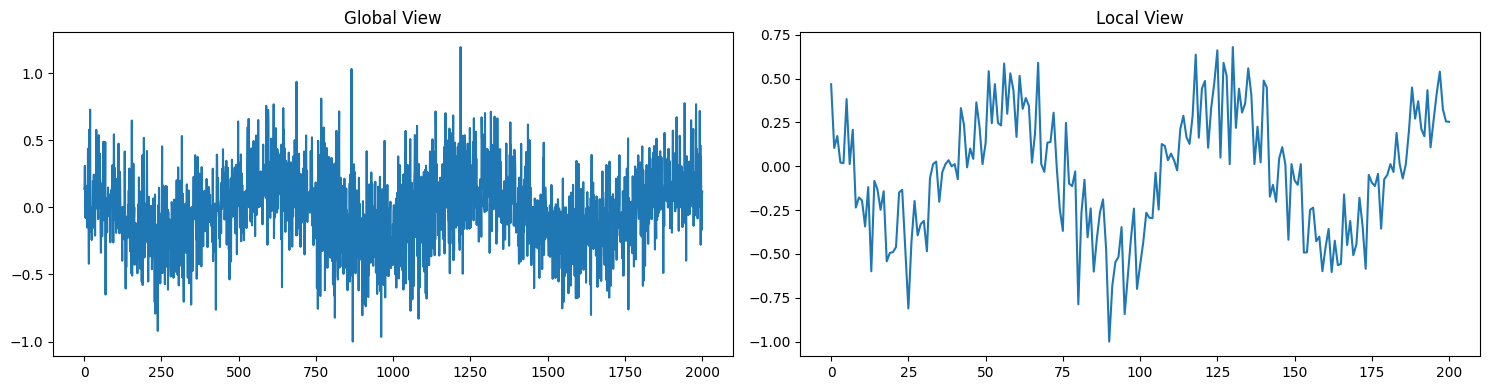

In [57]:
#one final vis before model training

import matplotlib.pyplot as plt

fig, ax = plt.subplots(1, 2, figsize=(15, 4))

ax[0].plot(glob_norm)
ax[0].set_title("Global View")

ax[1].plot(loc_norm)
ax[1].set_title("Local View")

plt.tight_layout()
plt.show()


The Global and Local views look similar because this candidate's transit duration is unusually large relative to its orbital period, causing the local zoom window to cover almost the entire folded orbit.

Build reusable functions for light-curve processing

In [58]:
def load_lc(kepid):
    
    search = lk.search_lightcurve(
        f"KIC {kepid}",
        mission="Kepler",
        cadence="long"
    )

    return (
        search
        .download_all()
        .stitch()
        .remove_nans()
    )

In [59]:
def binned(phase, flux, lo, hi, n):
    
    edges = np.linspace(lo, hi, n + 1)
    
    idx = np.digitize(
        phase,
        edges
    ) - 1

    out = np.array([
        np.median(flux[idx == i])
        if (idx == i).any()
        else np.nan
        for i in range(n)
    ])

    out[np.isnan(out)] = np.nanmedian(out)

    return out

In [60]:
def make_views(
    lc,
    period,
    t0,
    duration_hr
):

    dur = duration_hr / 24

    mask = lc.create_transit_mask(
        period=period,
        transit_time=t0,
        duration=2 * dur
    )

    flat = lc.flatten(
        window_length=401,
        mask=mask
    )

    t = flat.time.value
    f = flat.flux.value

    phase = (
        (t - t0 + period / 2)
        % period
    ) - period / 2

    glob = binned(
        phase,
        f,
        -period / 2,
        period / 2,
        2001
    )

    loc = binned(
        phase,
        f,
        -4 * dur,
        4 * dur,
        201
    )

    depth = 1 - np.median(
        f[np.abs(phase) < dur / 2]
    )

    norm = lambda v: (
        v - np.median(v)
    ) / abs(
        (v - np.median(v)).min()
    )

    return (
        norm(glob),
        norm(loc),
        depth
    )

In [61]:
row = train.iloc[0]

lc = load_lc(
    row["kepid"]
)

glob, loc, depth = make_views(
    lc,
    row["tce_period"],
    row["tce_time0bk"],
    row["tce_duration"]
)

print(glob.shape)
print(loc.shape)
print(depth)

(2001,)
(201,)
2.2492859982126134e-05


In [62]:
sample_rows = train.head(5)

for idx, row in sample_rows.iterrows():

    try:

        lc = load_lc(
            row["kepid"]
        )

        glob, loc, depth = make_views(
            lc,
            row["tce_period"],
            row["tce_time0bk"],
            row["tce_duration"]
        )

        print(
            row["kepid"],
            glob.shape,
            loc.shape,
            row["planet"]
        )

    except Exception as e:

        print(
            row["kepid"],
            "FAILED",
            e
        )


1162345 (2001,) (201,) 0
1162345 (2001,) (201,) 0
892667 (2001,) (201,) 0
892772 (2001,) (201,) 0
1160891 (2001,) (201,) 0


Baseline Model

In [64]:
baseline_df = train.head(100).copy()

#use a subset

In [65]:
#compute depth for each sample

depths = []

for idx, row in baseline_df.iterrows():

    try:

        lc = load_lc(
            row["kepid"]
        )

        _, _, depth = make_views(
            lc,
            row["tce_period"],
            row["tce_time0bk"],
            row["tce_duration"]
        )

        depths.append(depth)

    except:

        depths.append(np.nan)

In [66]:
#add depth

baseline_df["depth"] = depths

In [67]:
#remove failures

baseline_df = baseline_df.dropna(
    subset=["depth"]
)

In [68]:
#verify

baseline_df[
    [
        "tce_period",
        "tce_duration",
        "depth",
        "planet"
    ]
].head()

,tce_period,tce_duration,depth,planet
0,0.831850,2.392,2.2492859982126134e-05,0
3,0.831833,2.181,3.055528076401082e-05,0
6,2.262110,7.509,0.0002602731341109221,0
7,5.092600,3.399,0.00019343749645306385,0
15,0.940463,3.332,-4.951010774689735e-05,0


Train the baseline model

In [69]:
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import roc_auc_score

In [70]:
#create features
features = [
    "tce_period",
    "tce_duration",
    "depth"
]

X = baseline_df[features]
y = baseline_df["planet"]

In [71]:
#train
baseline_model = HistGradientBoostingClassifier(
    random_state=SEED
)

baseline_model.fit(X, y)

,loss,'log_loss'
,learning_rate,0.1
,max_iter,100
,max_leaf_nodes,31
,max_depth,None
,min_samples_leaf,20
,l2_regularization,0.0
,max_features,1.0
,max_bins,255
,categorical_features,'from_dtype'
,monotonic_cst,None


In [72]:
#predict
preds = baseline_model.predict_proba(X)[:, 1]

In [73]:
#evaluate
auc = roc_auc_score(
    y,
    preds
)

print("AUC:", auc)

AUC: 0.9984939759036146


train
↓
fit
↓
predict on same train

is the reason for artificially high auc, baseline is just to verify our pipeline of what we are doing the real game comes in with the CNN, which is our next step

CNN dataset creation

In [75]:
cnn_data = []

#start with 20 samples
sample_rows = train.head(20)

In [76]:
#generate CNN samples

for _, row in sample_rows.iterrows():

    try:

        lc = load_lc(
            row["kepid"]
        )

        glob, loc, depth = make_views(
            lc,
            row["tce_period"],
            row["tce_time0bk"],
            row["tce_duration"]
        )

        cnn_data.append(
            {
                "global_view": glob,
                "local_view": loc,
                "label": row["planet"]
            }
        )

        print(
            f"Processed {row['kepid']}"
        )

    except Exception as e:

        print(
            f"Failed {row['kepid']}: {e}"
        )

Processed 1162345
Processed 1162345
Processed 892667
Processed 892772
Processed 1160891
Processed 1160891
Processed 1160891
Processed 1162150
Processed 1162150
Processed 1161345
Processed 1162345
Processed 1292087
Processed 1573174
Processed 1575690
Processed 1575873
Processed 1865567
Processed 1865567
Processed 1865567
Processed 2019227
Processed 2019477


In [77]:
#verify dataset
print("Samples:", len(cnn_data))

Samples: 20


In [78]:
#inspect 1st sample
cnn_data[0].keys()

dict_keys(['global_view', 'local_view', 'label'])

In [79]:
#check shapes
print(
    cnn_data[0]["global_view"].shape
)

print(
    cnn_data[0]["local_view"].shape
)

print(
    cnn_data[0]["label"]
)

(2001,)
(201,)
0


CNN Dataset Optimization

introducing caching

In [80]:
lc_cache = {}

def load_lc(kepid):

    if kepid in lc_cache:
        return lc_cache[kepid]

    search = lk.search_lightcurve(
        f"KIC {kepid}",
        mission="Kepler",
        cadence="long"
    )

    lc = (
        search
        .download_all()
        .stitch()
        .remove_nans()
    )

    lc_cache[kepid] = lc

    return lc

In [81]:
print("Unique Stars:", train["kepid"].nunique())
print("Total TCEs:", len(train))

Unique Stars: 8878
Total TCEs: 14193


We are making sure the same star is downloaded only once and reused for all its TCEs, which dramatically speeds up preprocessing because multiple signals can belong to the same star.

In [82]:
print(len(lc_cache))

0


In [83]:
train["kepid"].nunique()
len(train)

14193

convert cnn samples to arrays

We are converting our Python dictionaries into matrix form so that the data can be consumed directly by a neural network framework such as PyTorch.

In [84]:
X_global = np.array(
    [x["global_view"] for x in cnn_data]
)

X_local = np.array(
    [x["local_view"] for x in cnn_data]
)

y = np.array(
    [x["label"] for x in cnn_data]
)


In [85]:
print(X_global.shape)
print(X_local.shape)
print(y.shape)

(20, 2001)
(20, 201)
(20,)


CNN Architecture Prototype

Global View Branch
        \
         \
          Dense Layers
         /
        /
Local View Branch

In [99]:
import torch
import torch.nn as nn

In [100]:
#convert arrays to tensors
X_global = np.array(
    [x["global_view"] for x in cnn_data]
)

X_local = np.array(
    [x["local_view"] for x in cnn_data]
)

y = np.array(
    [x["label"] for x in cnn_data]
)

In [101]:
X_global = torch.tensor(
    X_global,
    dtype=torch.float32
)

X_local = torch.tensor(
    X_local,
    dtype=torch.float32
)

y = torch.tensor(
    y,
    dtype=torch.float32
)

In [102]:
X_global_batch = X_global.unsqueeze(1)

X_local_batch = X_local.unsqueeze(1)

In [103]:
print(X_global_batch.shape)
print(X_local_batch.shape)

torch.Size([20, 1, 2001])
torch.Size([20, 1, 201])


In [104]:
class ExoplanetCNN(nn.Module):

    def __init__(self):

        super().__init__()

        self.global_branch = nn.Sequential(
            nn.Conv1d(1, 16, kernel_size=5),
            nn.ReLU(),
            nn.MaxPool1d(2),

            nn.Conv1d(16, 32, kernel_size=5),
            nn.ReLU(),
            nn.MaxPool1d(2)
        )

        self.local_branch = nn.Sequential(
            nn.Conv1d(1, 16, kernel_size=5),
            nn.ReLU(),
            nn.MaxPool1d(2),

            nn.Conv1d(16, 32, kernel_size=5),
            nn.ReLU(),
            nn.MaxPool1d(2)
        )

        with torch.no_grad():

            dummy_global = torch.zeros(
                1, 1, 2001
            )

            dummy_local = torch.zeros(
                1, 1, 201
            )

            g = self.global_branch(
                dummy_global
            )

            l = self.local_branch(
                dummy_local
            )

            feature_size = (
                g.view(1, -1).shape[1]
                +
                l.view(1, -1).shape[1]
            )

        self.fc = nn.Sequential(
            nn.Linear(
                feature_size,
                128
            ),
            nn.ReLU(),

            nn.Linear(
                128,
                1
            ),

            nn.Sigmoid()
        )

    def forward(
        self,
        global_view,
        local_view
    ):

        g = self.global_branch(
            global_view
        )

        l = self.local_branch(
            local_view
        )

        g = g.view(
            g.size(0),
            -1
        )

        l = l.view(
            l.size(0),
            -1
        )

        x = torch.cat(
            [g, l],
            dim=1
        )

        return self.fc(x)

In [105]:
#instantiate
model = ExoplanetCNN()

model

ExoplanetCNN(
  (global_branch): Sequential(
    (0): Conv1d(1, 16, kernel_size=(5,), stride=(1,))
    (1): ReLU()
    (2): MaxPool1d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv1d(16, 32, kernel_size=(5,), stride=(1,))
    (4): ReLU()
    (5): MaxPool1d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (local_branch): Sequential(
    (0): Conv1d(1, 16, kernel_size=(5,), stride=(1,))
    (1): ReLU()
    (2): MaxPool1d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv1d(16, 32, kernel_size=(5,), stride=(1,))
    (4): ReLU()
    (5): MaxPool1d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (fc): Sequential(
    (0): Linear(in_features=17408, out_features=128, bias=True)
    (1): ReLU()
    (2): Linear(in_features=128, out_features=1, bias=True)
    (3): Sigmoid()
  )
)

In [109]:
#forward pass
with torch.no_grad():

    output = model(
        X_global_batch,
        X_local_batch
    )

In [110]:
output.shape

torch.Size([20, 1])

In [111]:
#prepare batch dimension
X_global_batch = X_global.unsqueeze(1)
X_local_batch = X_local.unsqueeze(1)

print(X_global_batch.shape)
print(X_local_batch.shape)

torch.Size([20, 1, 2001])
torch.Size([20, 1, 201])
